In [1]:
import pandas as pd
import numpy as np
from mlxtend.plotting import plot_decision_regions

In [2]:
df=pd.DataFrame()
df['x1']=[1,2,3,4,5,6,6,7,9,9]
df['x2']=[5,3,6,8,1,9,5,8,9,2]
df['label']=[1,1,0,1,0,1,0,1,0,0]
df.head(10)

,x1,x2,label
0,1,5,1
1,2,3,1
2,3,6,0
3,4,8,1
4,5,1,0
5,6,9,1
6,6,5,0
7,7,8,1
8,9,9,0
9,9,2,0


<Axes: xlabel='x1', ylabel='x2'>

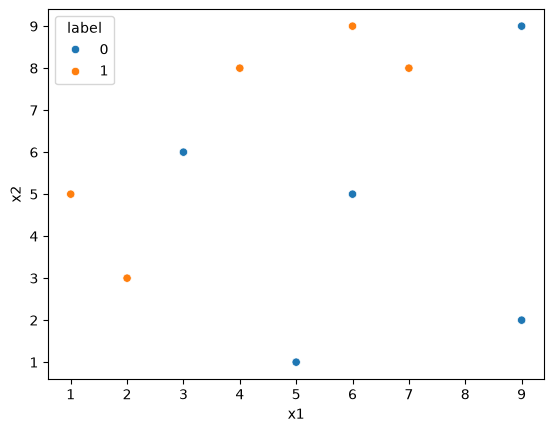

In [3]:
import seaborn as sns 
sns.scatterplot(x=df['x1'],y=df['x2'],hue=df['label'])


In [4]:
df['weight']=1/df.shape[0]
df.head(5)

,x1,x2,label,weight
0,1,5,1,0.1
1,2,3,1,0.1
2,3,6,0,0.1
3,4,8,1,0.1
4,5,1,0,0.1


In [5]:
from sklearn.tree import DecisionTreeClassifier

dt=DecisionTreeClassifier(max_depth=1)

<Axes: >

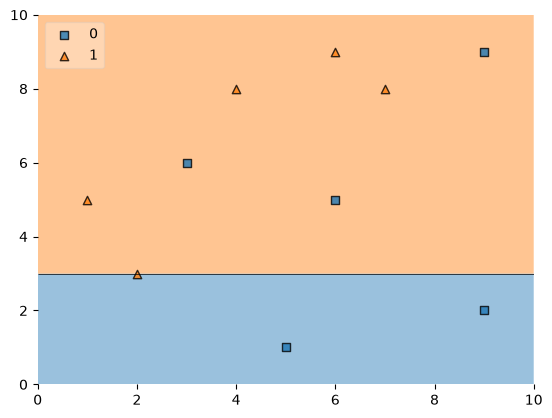

In [6]:
x = df[['x1', 'x2']].values
y = df['label'].values
dt.fit(x, y)
plot_decision_regions(x,y,clf=dt,legend=2)

In [7]:
df['predict']=dt.predict(x)
df.head(10)

,x1,x2,label,weight,predict
0,1,5,1,0.1,1
1,2,3,1,0.1,1
2,3,6,0,0.1,1
3,4,8,1,0.1,1
4,5,1,0,0.1,0
5,6,9,1,0.1,1
6,6,5,0,0.1,1
7,7,8,1,0.1,1
8,9,9,0,0.1,1
9,9,2,0,0.1,0


In [8]:
error=df[df['label'] != df['predict']].shape[0]
error=error*0.1
error

0.30000000000000004

In [9]:
alpha1= 0.5 * np.log((1-error)/error)
alpha1

np.float64(0.4236489301936017)

In [10]:
def update_weight(df,alpha=alpha1) :
    if(df['label'] == df['predict']) : 
        return df['weight'] * np.exp(-alpha)
    else : 
        return df['weight'] * np.exp(alpha)

In [11]:
df['weight2']=df.apply(update_weight,axis=1)
df.head(10)

,x1,x2,label,weight,predict,weight2
0,1,5,1,0.1,1,0.065465
1,2,3,1,0.1,1,0.065465
2,3,6,0,0.1,1,0.152753
3,4,8,1,0.1,1,0.065465
4,5,1,0,0.1,0,0.065465
5,6,9,1,0.1,1,0.065465
6,6,5,0,0.1,1,0.152753
7,7,8,1,0.1,1,0.065465
8,9,9,0,0.1,1,0.152753
9,9,2,0,0.1,0,0.065465


In [12]:
n=df['weight2'].sum()
df['weight2']=df['weight2']/n
print(f"sum = {df['weight2'].sum()}")
display(df.head(10))

sum = 0.9999999999999999


,x1,x2,label,weight,predict,weight2
0,1,5,1,0.1,1,0.071429
1,2,3,1,0.1,1,0.071429
2,3,6,0,0.1,1,0.166667
3,4,8,1,0.1,1,0.071429
4,5,1,0,0.1,0,0.071429
5,6,9,1,0.1,1,0.071429
6,6,5,0,0.1,1,0.166667
7,7,8,1,0.1,1,0.071429
8,9,9,0,0.1,1,0.166667
9,9,2,0,0.1,0,0.071429


In [13]:
df['cumsum_upper'] = np.cumsum(df['weight2'])

df['cumsum_lower'] = df['cumsum_upper'] - df['weight2']
df.head(10)


,x1,x2,label,weight,predict,weight2,cumsum_upper,cumsum_lower
0,1,5,1,0.1,1,0.071429,0.071429,0.000000
1,2,3,1,0.1,1,0.071429,0.142857,0.071429
2,3,6,0,0.1,1,0.166667,0.309524,0.142857
3,4,8,1,0.1,1,0.071429,0.380952,0.309524
4,5,1,0,0.1,0,0.071429,0.452381,0.380952
5,6,9,1,0.1,1,0.071429,0.523810,0.452381
6,6,5,0,0.1,1,0.166667,0.690476,0.523810
7,7,8,1,0.1,1,0.071429,0.761905,0.690476
8,9,9,0,0.1,1,0.166667,0.928571,0.761905
9,9,2,0,0.1,0,0.071429,1.000000,0.928571


In [15]:
def update_dataset(df) :
    ind=[]
    for iter in range(df.shape[0]) :
        a=np.random.random()
        for index,row in df.iterrows() :
            if ((a>=row['cumsum_lower']) and (a<=row['cumsum_upper'])) :
                ind.append(index)
    return ind


In [16]:
ind=update_dataset(df)
ind

[7, 0, 0, 2, 2, 8, 2, 8, 3, 2]

In [19]:
df2=df.iloc[ind].iloc[:,:3]
df2=pd.DataFrame(df2)
df2=df2.reset_index(drop=True)
df2.head(10)

,x1,x2,label
0,7,8,1
1,1,5,1
2,1,5,1
3,3,6,0
4,3,6,0
5,9,9,0
6,3,6,0
7,9,9,0
8,4,8,1
9,3,6,0
